# Prueba 03-2

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import UpROOT.io as io
import UpROOT.config as conf
import UpROOT.physics.delphes as ph
import UpROOT.plotting.delphes as pt
import UpROOT.pipelines.delphes as pl

In [3]:
ANALYSIS = 'smf03'
cfg = conf.CONFIGURATIONS[ANALYSIS]
DATASET = cfg['raw_dataset']
PDATASET = cfg['flat_dataset']
PLOT_DATA = cfg['plot_data']
TARGET_MASS = None
MASS_RANGE = cfg['mass_range']
FIT_WINDOW = cfg['fit_window']
MIN_MUON_PT = 0.0
ETA_RANGE = (2.0, 5.0)

plot_options = {
    'save': True,
    'data': PLOT_DATA,
    'output_dir': None
}

In [4]:
# cut = '(Eta < 5.0) & (Eta > 2)'
MUON_BRANCHES = (
    'event_id',
    'object_index',
    'PT',
    'Eta',
    'Phi',
    'Charge',
    'D0',
    'DZ',
    'ErrorD0',
    'ErrorDZ',
    'IsolationVar',
    'Particle_ref'
)

In [5]:
df_events = io.load_dataframe(
    branches=None,
    dataset=PDATASET,
    tree_path='Events',
)
df_events.head()

Archivo: dimuons03_pandas.root
Árbol seleccionado: Events
Total de eventos: 400,000 eventos


,source_file_id,event_id,source_entry,root_uid,event_number,ReadTime,ProcTime,ProcessID,MPI,event_weight,...,PDF1,PDF2,n_EFlowTrack,n_Electron,n_Jet,n_Muon,n_Particle,n_ScalarHT,n_Track,n_Weight
0,0,0,0,0,0,0.506989,0.009800,9999,-1,40990.117188,...,inf,inf,3,0,0,2,578,1,11,292
1,0,1,1,0,1,0.001399,0.001059,9999,-1,35096.382812,...,inf,inf,0,0,0,0,251,1,1,292
2,0,2,2,0,2,0.001357,0.000654,9999,-1,60.626938,...,inf,inf,1,0,0,0,221,1,3,292
3,0,3,3,0,3,0.000561,0.000407,9999,-1,35002.351562,...,inf,inf,0,0,0,0,130,1,0,292
4,0,4,4,0,4,0.002827,0.001104,9999,-1,-0.028055,...,inf,inf,2,0,0,0,642,1,13,292


In [6]:
df_muons = io.load_dataframe(
    branches=MUON_BRANCHES,
    dataset=PDATASET,
    tree_path='Muons'
)
df_muons.head(7)

Archivo: dimuons03_pandas.root
Árbol seleccionado: Muons
Total de eventos: 155,861 eventos


,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref
0,0,0,1.118285,3.036834,2.304429,-1,-0.028890,0.0,-0.006414,0.0,0.126076,158
1,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,0.136532,157
2,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,0.000000,96
3,5,1,0.929687,3.645410,-1.688336,-1,-0.008104,0.0,0.008238,0.0,0.000000,97
4,7,0,0.919755,3.423170,2.048764,-1,-0.057072,0.0,-0.000494,0.0,0.000000,16
5,11,0,1.303808,3.976871,-1.248847,-1,-0.063595,0.0,-0.016322,0.0,0.000000,48
6,15,0,1.733335,3.302351,2.582864,1,-0.013200,0.0,0.028962,0.0,0.000000,93


In [7]:
cdf_muons = df_muons.loc[
    df_muons['PT'].ge(MIN_MUON_PT) & 
    df_muons['Eta'].between(*ETA_RANGE)
].copy()
print(f'Muones totales:       {len(df_muons):,}')
print(f'Muones seleccionados: {len(cdf_muons):,}')

Muones totales:       155,861
Muones seleccionados: 155,861


In [8]:
df_muons = ph.calc_four_momentum(df_muons)
df_muons.head()

,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref,PX,PY,PZ,P,E
0,0,0,1.118285,3.036834,2.304429,-1,-0.028890,0.0,-0.006414,0.0,0.126076,158,-0.748772,0.830603,11.625232,11.678895,11.679373
1,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,0.136532,157,0.143573,-0.882595,18.355015,18.376783,18.377087
2,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,0.000000,96,-3.617196,2.272123,141.846406,141.910710,141.910749
3,5,1,0.929687,3.645410,-1.688336,-1,-0.008104,0.0,0.008238,0.0,0.000000,97,-0.109023,-0.923272,17.790652,17.814927,17.815240
4,7,0,0.919755,3.423170,2.048764,-1,-0.057072,0.0,-0.000494,0.0,0.000000,16,-0.423065,0.816680,14.087832,14.117825,14.118220


In [9]:
cdf_muons = ph.calc_four_momentum(cdf_muons)
cdf_muons.head()

,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref,PX,PY,PZ,P,E
0,0,0,1.118285,3.036834,2.304429,-1,-0.028890,0.0,-0.006414,0.0,0.126076,158,-0.748772,0.830603,11.625232,11.678895,11.679373
1,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,0.136532,157,0.143573,-0.882595,18.355015,18.376783,18.377087
2,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,0.000000,96,-3.617196,2.272123,141.846406,141.910710,141.910749
3,5,1,0.929687,3.645410,-1.688336,-1,-0.008104,0.0,0.008238,0.0,0.000000,97,-0.109023,-0.923272,17.790652,17.814927,17.815240
4,7,0,0.919755,3.423170,2.048764,-1,-0.057072,0.0,-0.000494,0.0,0.000000,16,-0.423065,0.816680,14.087832,14.117825,14.118220


In [10]:
df_dimuons = pl.prepare_dimuon_analysis(
    df_muons,
    events=df_events
)
df_dimuons.head()

,event_id,muplus_index,muplus_pt,muplus_eta,muplus_phi,muplus_charge,muplus_d0,muplus_d_z,muplus_error_d0,muplus_error_d_z,...,delta_eta,delta_phi,delta_r,dimuon_charge,dimuon_mass2,muon_sum_pt,pt_balance,acoplanarity,dimuon_rapidity,cos_theta_star
0,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,...,0.678638,2.569219,2.657336,0,4.206583,2.012481,0.111349,0.572373,3.334593,-0.326869
1,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,...,0.550718,-2.014115,2.088049,0,12.697224,5.201296,0.642517,1.127478,4.093110,-0.268604
2,15,0,1.733335,3.302351,2.582864,1,-0.013200,0.0,0.028962,0.0,...,-1.225230,-0.634274,1.379671,0,4.827171,3.051990,0.135872,2.507319,3.838550,0.545965
3,21,0,4.213566,3.521155,2.526603,1,0.040786,0.0,-0.010319,0.0,...,0.663101,-2.762170,2.840648,0,50.037975,6.963199,0.210239,0.379423,3.256416,-0.319913
4,27,0,2.000266,3.616623,-0.761206,1,0.017056,0.0,-0.001670,0.0,...,0.431102,-2.419466,2.457573,0,8.251542,3.110588,0.286101,0.722127,3.459056,-0.212273


In [11]:
display(df_dimuons[[
    "event_id", "dimuon_mass", "dimuon_pt", "delta_r"
]].head())

,event_id,dimuon_mass,dimuon_pt,delta_r
0,0,2.050996,0.607428,2.657336
1,5,3.563316,3.962841,2.088049
2,15,2.197082,2.902675,1.379671
3,21,7.073753,1.947073,2.840648
4,27,2.872550,1.378653,2.457573


In [12]:
cdf_dimuons = pl.prepare_dimuon_analysis(
    cdf_muons, 
    events=df_events
)
cdf_dimuons.head(7)

,event_id,muplus_index,muplus_pt,muplus_eta,muplus_phi,muplus_charge,muplus_d0,muplus_d_z,muplus_error_d0,muplus_error_d_z,...,delta_eta,delta_phi,delta_r,dimuon_charge,dimuon_mass2,muon_sum_pt,pt_balance,acoplanarity,dimuon_rapidity,cos_theta_star
0,0,1,0.894197,3.715472,-1.409537,1,-0.062964,0.0,-0.017734,0.0,...,0.678638,2.569219,2.657336,0,4.206583,2.012481,0.111349,0.572373,3.334593,-0.326869
1,5,0,4.271610,4.196128,2.580735,1,-0.007288,0.0,0.022104,0.0,...,0.550718,-2.014115,2.088049,0,12.697224,5.201296,0.642517,1.127478,4.093110,-0.268604
2,15,0,1.733335,3.302351,2.582864,1,-0.013200,0.0,0.028962,0.0,...,-1.225230,-0.634274,1.379671,0,4.827171,3.051990,0.135872,2.507319,3.838550,0.545965
3,21,0,4.213566,3.521155,2.526603,1,0.040786,0.0,-0.010319,0.0,...,0.663101,-2.762170,2.840648,0,50.037975,6.963199,0.210239,0.379423,3.256416,-0.319913
4,27,0,2.000266,3.616623,-0.761206,1,0.017056,0.0,-0.001670,0.0,...,0.431102,-2.419466,2.457573,0,8.251542,3.110588,0.286101,0.722127,3.459056,-0.212273
5,51,0,2.967119,2.357656,1.848857,1,-0.024062,0.0,-0.015057,0.0,...,-0.454642,-3.010141,3.044282,0,36.505976,5.897632,0.006207,0.131451,2.582958,0.223485
6,52,0,1.127463,4.665898,-3.077994,1,-0.046854,0.0,0.033020,0.0,...,-0.098558,-3.117553,3.119110,0,4.812700,2.182300,0.033280,0.024040,4.708883,0.049239


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\event_multiplicities_70GeV_01.png.


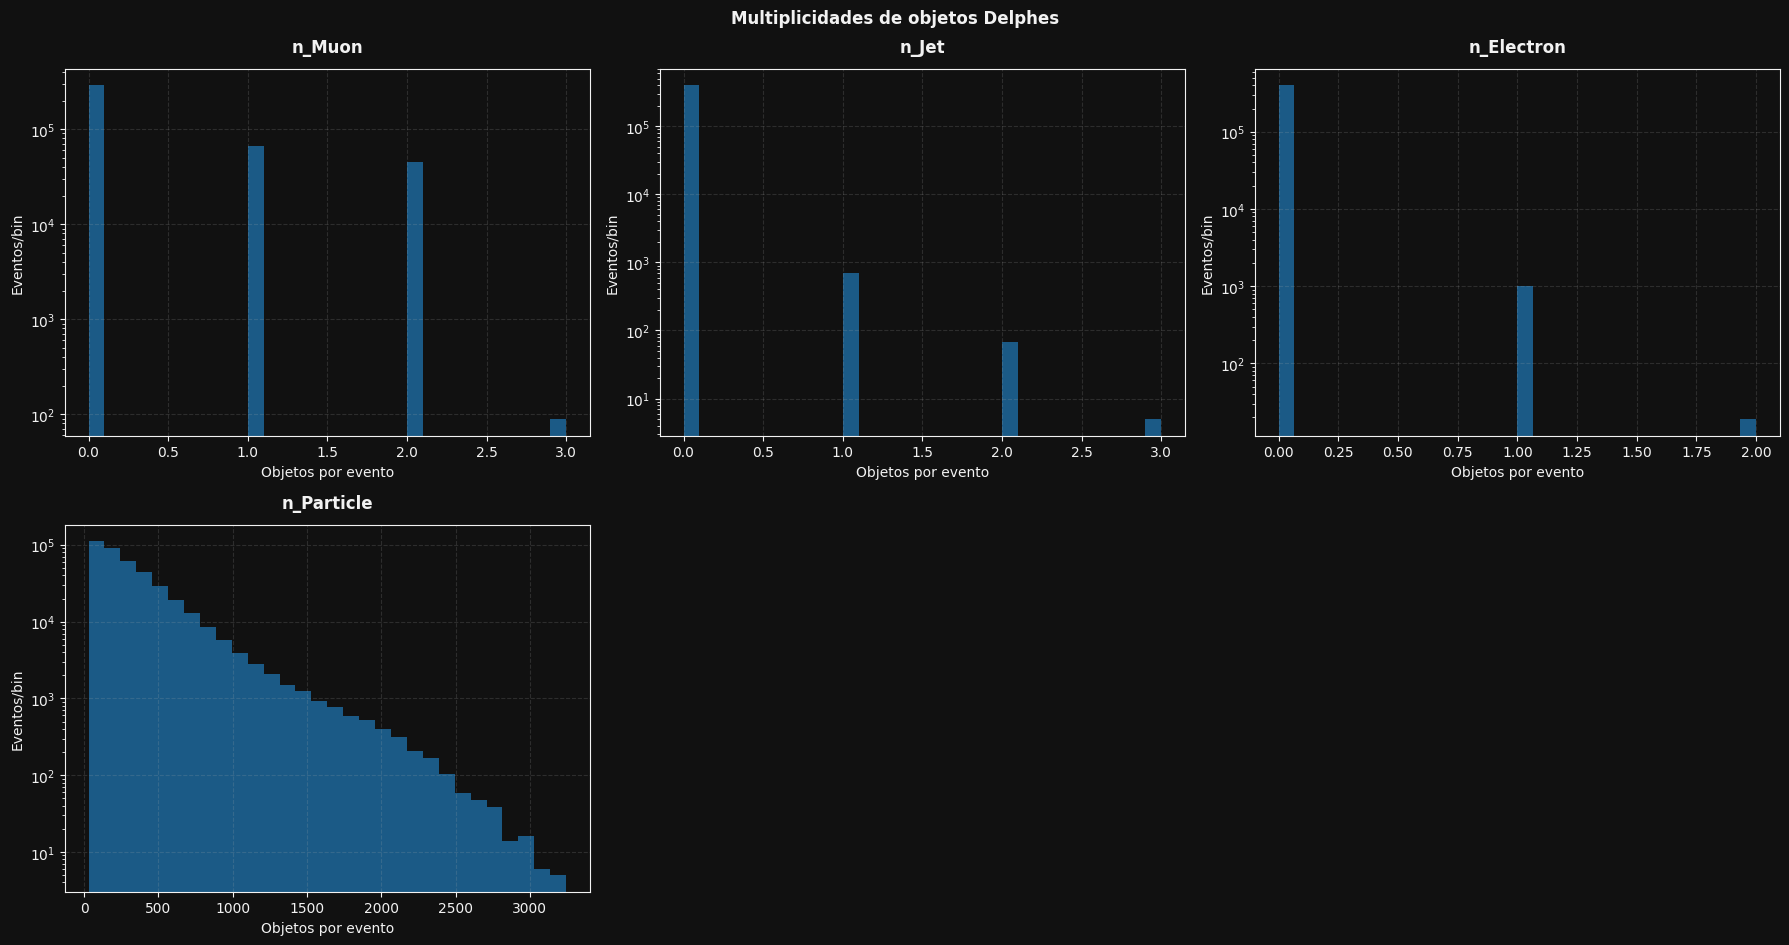

(<Figure size 1800x960 with 6 Axes>,
 array([[<Axes: title={'center': 'n_Muon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Jet'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Electron'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'n_Particle'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: >, <Axes: >]], dtype=object))

In [13]:
pt.plot_event_multiplicities(
    df_events,
    filename='event_multiplicities_70GeV_01',
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_01.png.


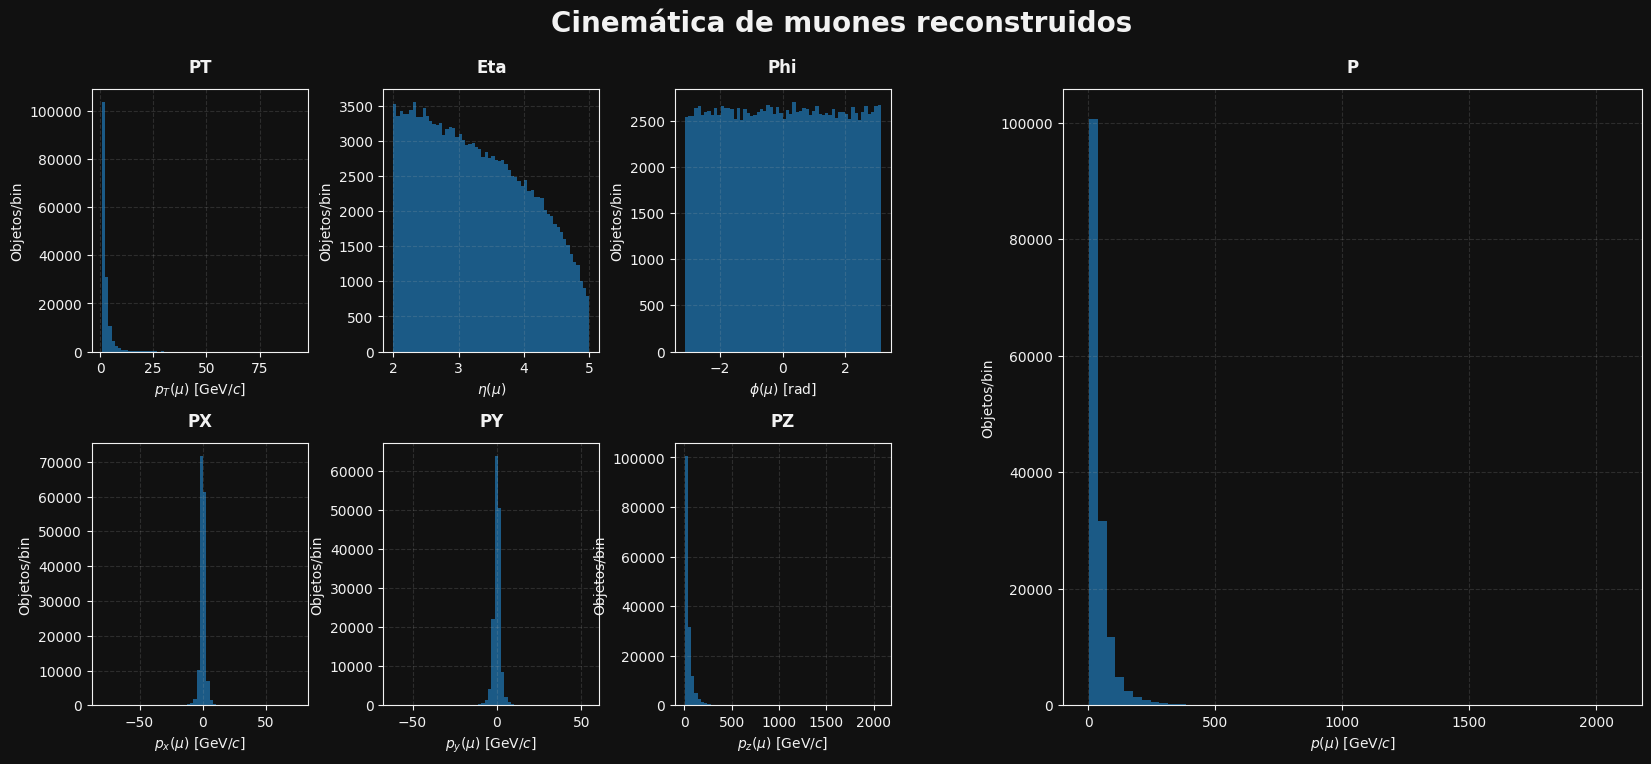

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>})

In [14]:
pt.plot_muon_kinematics(
    ph.calc_four_momentum(df_muons), 
    bins=60, 
    filename="muon_kinematics_70GeV_01",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_01_cut.png.


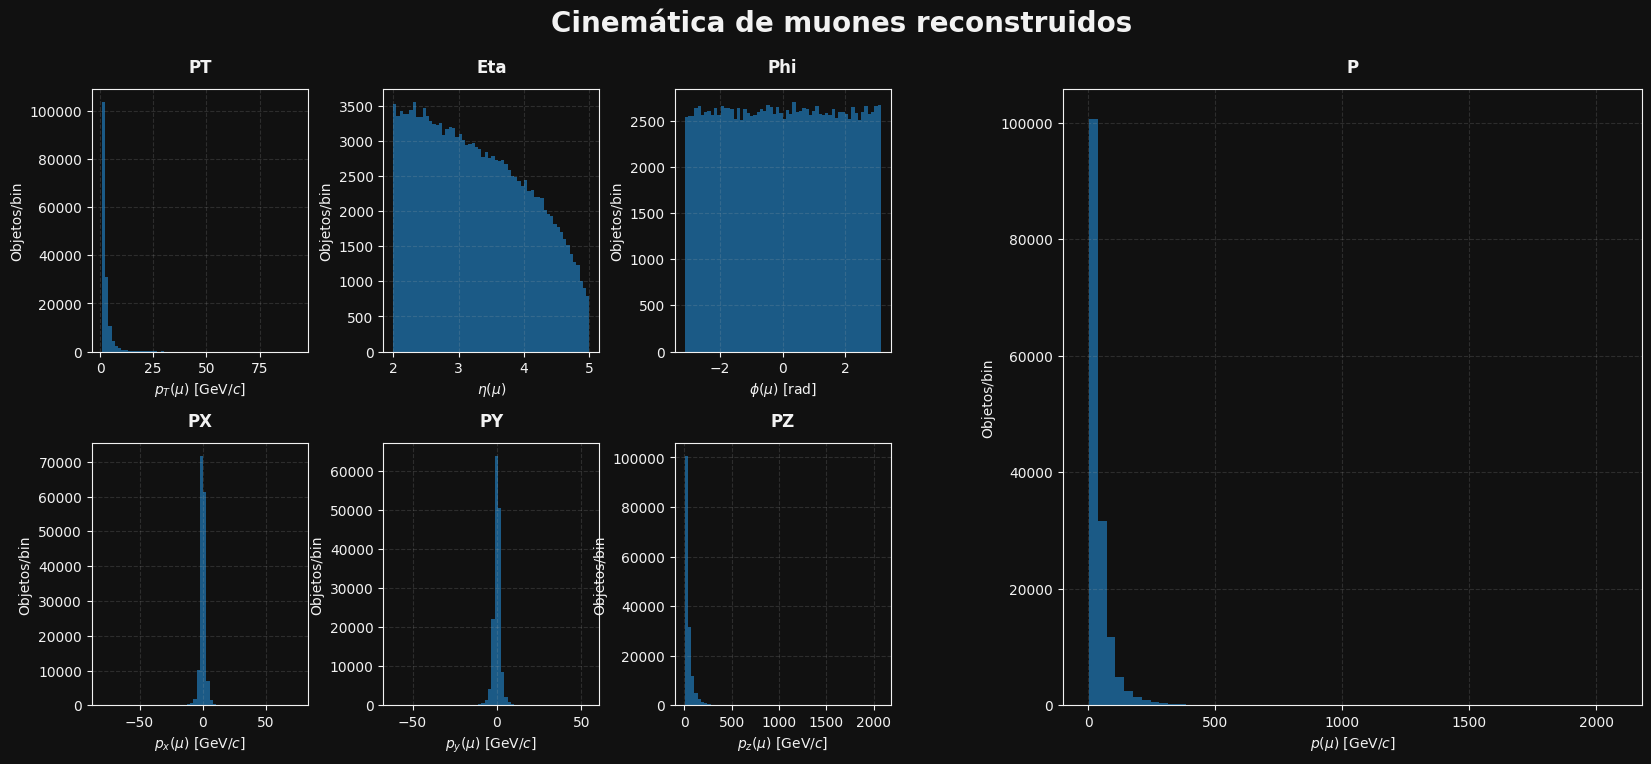

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>})

In [15]:
pt.plot_muon_kinematics(
    ph.calc_four_momentum(cdf_muons), 
    bins=60,
    filename="muon_kinematics_70GeV_01_cut",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_02.png.


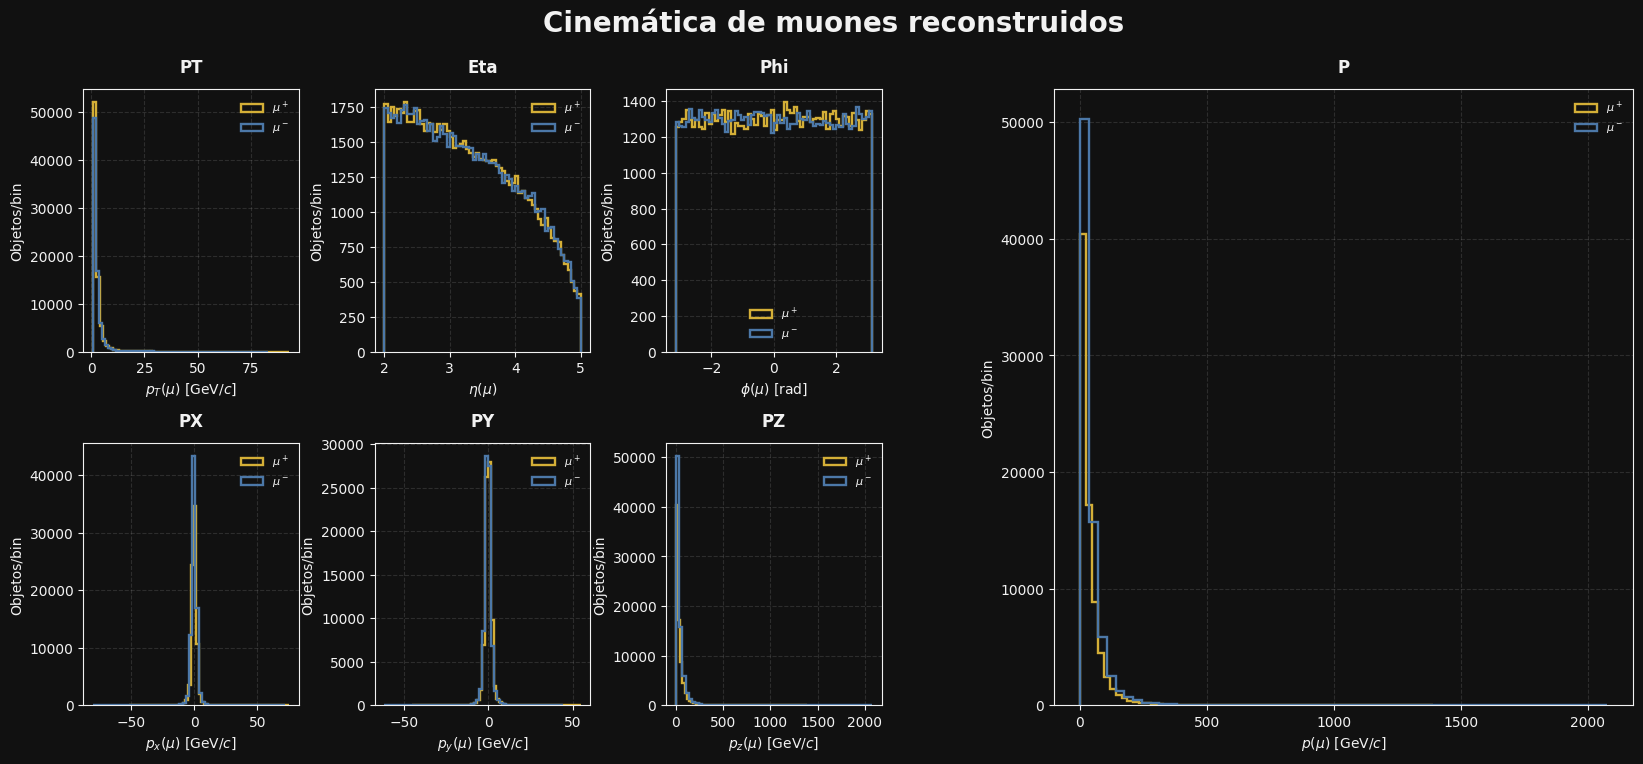

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>})

In [16]:
pt.plot_muon_kinematics(
    ph.calc_four_momentum(df_muons), 
    bins=60, 
    split_charge=True, 
    filename="muon_kinematics_70GeV_02",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\muon_kinematics_70GeV_02_cut.png.


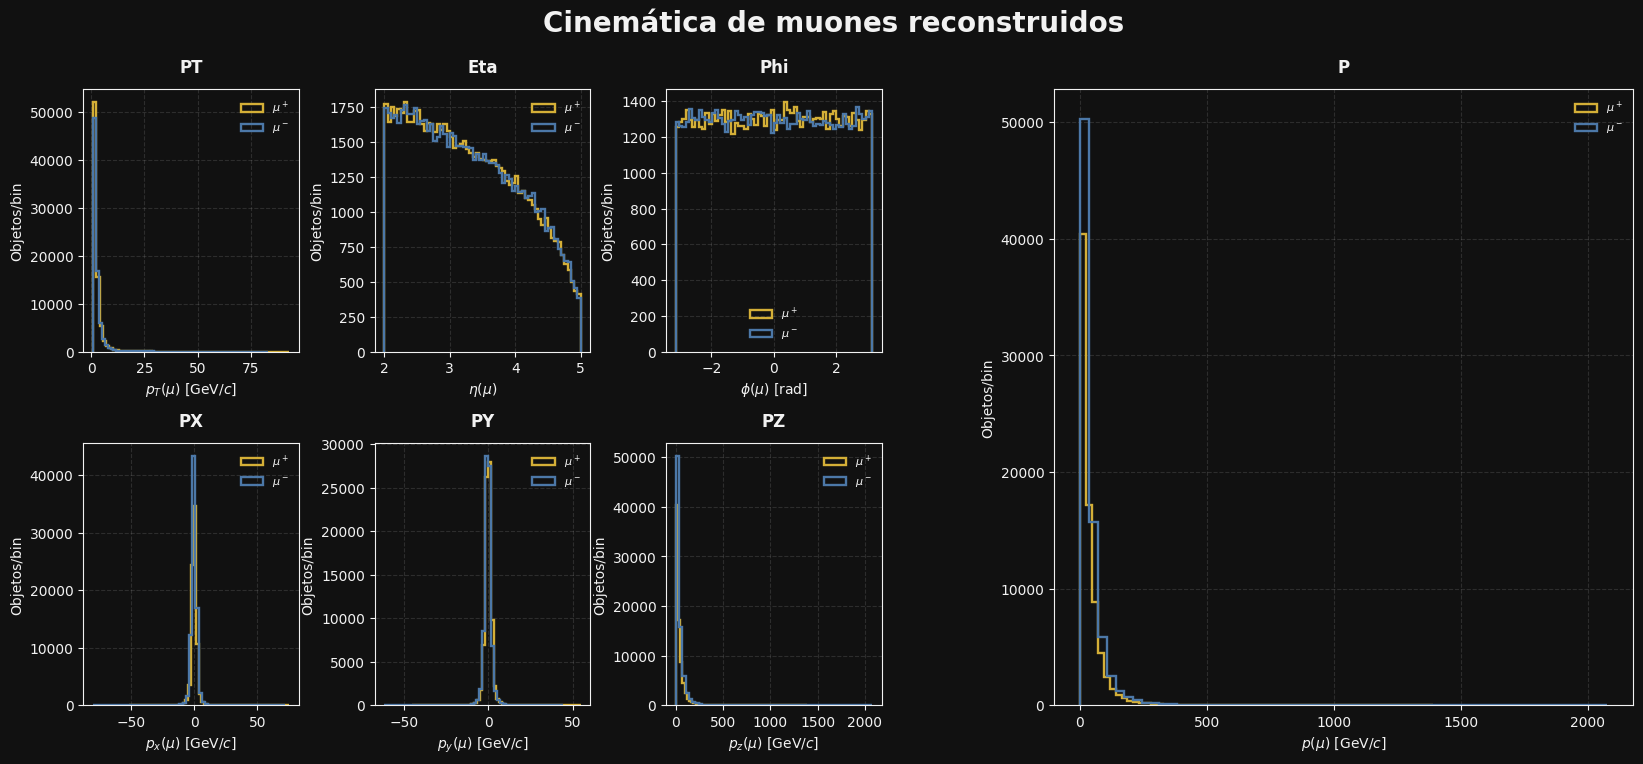

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Objetos/bin'>})

In [17]:
pt.plot_muon_kinematics(
    ph.calc_four_momentum(cdf_muons), 
    bins=60, 
    split_charge=True,
    filename="muon_kinematics_70GeV_02_cut",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\plotting\delphes.py:232: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\dimuon_mass_70GeV_01.png.


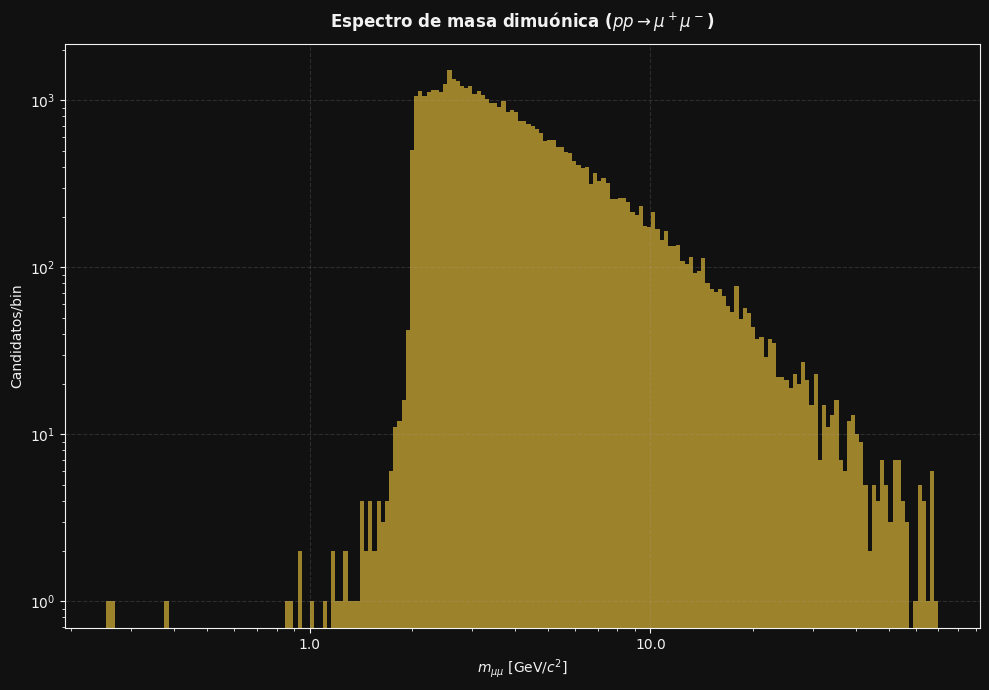

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Espectro de masa dimuónica ($pp\\to\\mu^+\\mu^-$)'}, xlabel='$m_{\\mu\\mu}$ [GeV/$c^2$]', ylabel='Candidatos/bin'>)

In [18]:
pt.plot_dimuon_mass(
    df_dimuons,
    bins=200, 
    log_x=True,
    log_y=True,
    mass_range=(0.0, 70.0),
    filename="dimuon_mass_70GeV_01",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\smf_model\c03\dimuon_mass_70GeV_01_cut.png.


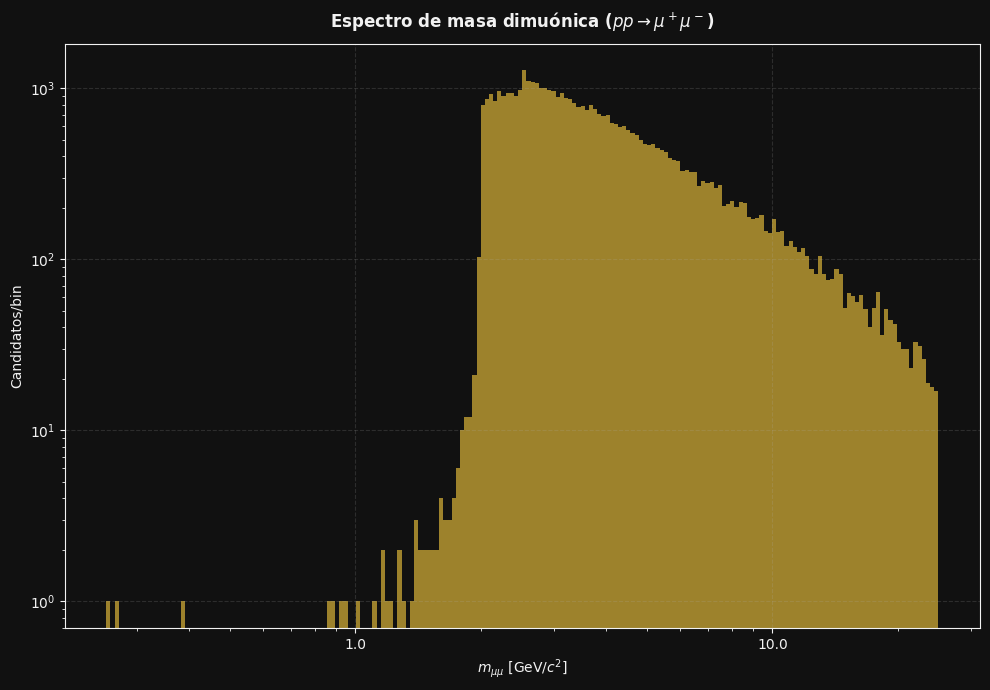

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Espectro de masa dimuónica ($pp\\to\\mu^+\\mu^-$)'}, xlabel='$m_{\\mu\\mu}$ [GeV/$c^2$]', ylabel='Candidatos/bin'>)

In [19]:
pt.plot_dimuon_mass(
    cdf_dimuons, 
    bins=200, 
    log_x=True,
    log_y=True,
    mass_range=(0.0, 25.0),
    filename="dimuon_mass_70GeV_01_cut",
    **plot_options
)